# Notebook 05 — Modelado Predictivo, Cuantiles CQR y SHAP

## Sensores Virtuales y Analizadores en Línea

En este notebook construimos y comparamos la jerarquía completa de modelos de nivel industrial:
1. **PLS (*Partial Least Squares*):** el estándar histórico en refinerías (AspenTech / Honeywell) frente a colinealidad.
2. **Modelos Lineales Regularizados:** Regresión Lineal, Ridge (L2) y Lasso (L1) con `StandardScaler` ajustado **solo en Train**.
3. **Modelos de Árboles y Boosting:** Random Forest, Gradient Boosting y **LightGBM + Optuna (40 trials)**.
4. **Regresión Cuantílica Conformalizada (CQR):** intervalos de predicción `P10–P90` (~80% de cobertura).
5. **Explicabilidad SHAP:** importancia global y cascadas locales (*waterfall*) para el operador.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import optuna
import lightgbm as lgb
import shap
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#007297", "#8EC14B", "#E8820C", "#C0392B", "#0D202B"]
WORK_DIR = "/content" if os.path.isdir("/content") else "."

df = pd.read_csv(os.path.join(WORK_DIR, "sensor_model_ready.csv"))
feature_cols = [c for c in df.columns if c not in ["date", "flash_point_lab_C", "split"]]

tr = df["split"] == "train"
va = df["split"] == "val"
te = df["split"] == "test"

X_train, y_train = df.loc[tr, feature_cols], df.loc[tr, "flash_point_lab_C"].values
X_val,   y_val   = df.loc[va, feature_cols], df.loc[va, "flash_point_lab_C"].values
X_test,  y_test  = df.loc[te, feature_cols], df.loc[te, "flash_point_lab_C"].values

# Escalador ajustado EXCLUSIVAMENTE sobre Train
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)} | Features: {len(feature_cols)}")

Train: 670 | Val: 153 | Test: 206 | Features: 25


=== Benchmark en Validación ===
           Modelo  MAE (°C)  RMSE (°C)    R2
Gradient Boosting     1.061      1.531 0.914
    LightGBM Base     1.092      1.553 0.912
 Regresión Lineal     1.426      1.832 0.877
    Random Forest     1.374      1.894 0.869
       Ridge (L2)     1.806      2.313 0.804
       Lasso (L1)     1.829      2.357 0.797
    PLS (4 comp.)     1.909      2.400 0.789


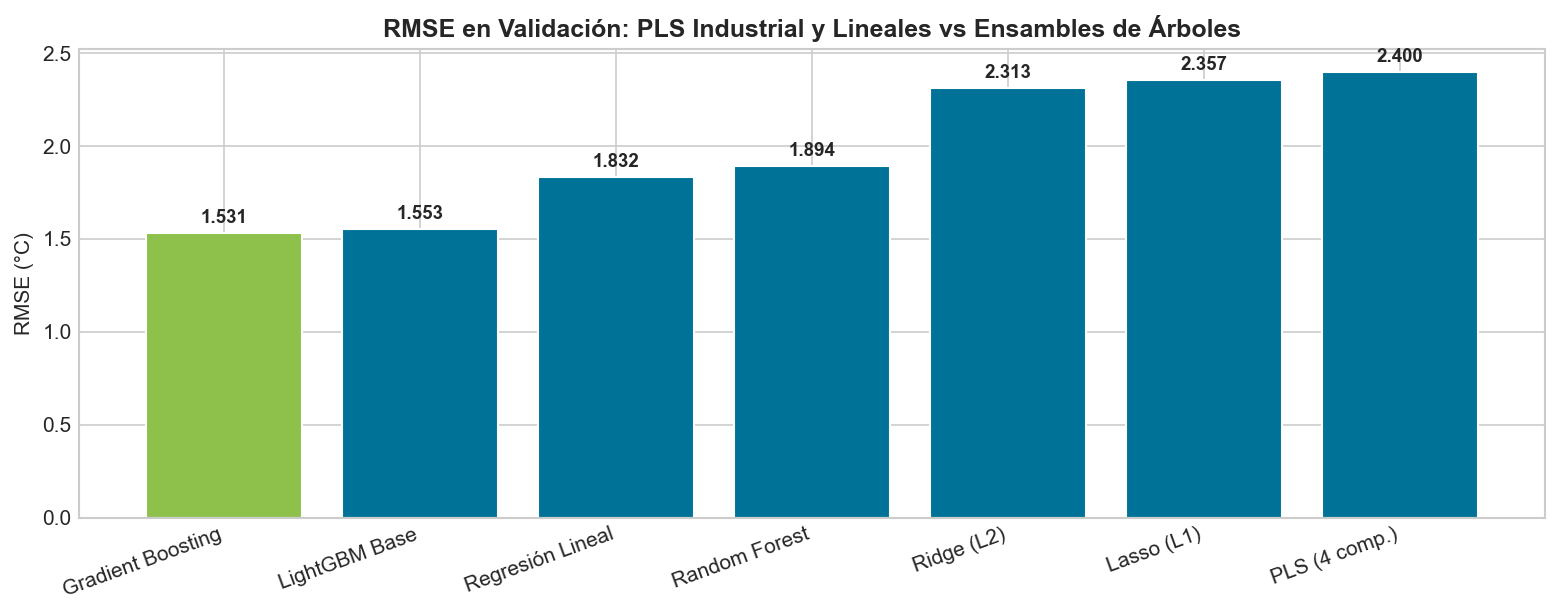

In [2]:
# Comparativa de 7 algoritmos en Validación (PLS industrial + Lineales + Árboles)
modelos = [
    ("PLS (4 comp.)",       PLSRegression(n_components=4), True),
    ("Regresión Lineal",    LinearRegression(), True),
    ("Ridge (L2)",          Ridge(alpha=10.0), True),
    ("Lasso (L1)",          Lasso(alpha=0.05), True),
    ("Random Forest",       RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1), False),
    ("Gradient Boosting",   GradientBoostingRegressor(n_estimators=250, learning_rate=0.04, max_depth=4, random_state=42), False),
    ("LightGBM Base",       lgb.LGBMRegressor(n_estimators=300, learning_rate=0.04, max_depth=5, num_leaves=20, min_child_samples=8, random_state=42, verbose=-1), False),
]

resultados = []
modelos_fit = {}
for nombre, modelo, usar_escalado in modelos:
    Xtr = X_train_s if usar_escalado else X_train
    Xva = X_val_s if usar_escalado else X_val
    modelo.fit(Xtr, y_train)
    preds = modelo.predict(Xva).ravel()
    resultados.append({
        "Modelo": nombre,
        "MAE (°C)": round(mean_absolute_error(y_val, preds), 3),
        "RMSE (°C)": round(np.sqrt(mean_squared_error(y_val, preds)), 3),
        "R2": round(r2_score(y_val, preds), 3),
    })
    modelos_fit[nombre] = modelo

df_res = pd.DataFrame(resultados).sort_values("RMSE (°C)").reset_index(drop=True)
print("=== Benchmark en Validación ===")
print(df_res.to_string(index=False))

fig, ax = plt.subplots(figsize=(10.5, 4.2), dpi=150)
bar_c = [COLORS[1] if i == 0 else COLORS[0] for i in range(len(df_res))]
bars = ax.bar(df_res["Modelo"], df_res["RMSE (°C)"], color=bar_c, edgecolor="white")
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9, fontweight="bold")
ax.set_title("RMSE en Validación: PLS Industrial y Lineales vs Ensambles de Árboles", fontsize=12, fontweight="bold")
ax.set_ylabel("RMSE (°C)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [3]:
# Optimización de hiperparámetros con Optuna (40 trials) sobre Validación
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 150, 450),
        "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.09, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 7),
        "num_leaves": trial.suggest_int("num_leaves", 10, 42),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 22),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 5.0, log=True),
        "random_state": 42, "n_jobs": -1, "verbose": -1,
    }
    m = lgb.LGBMRegressor(**params)
    m.fit(X_train, y_train)
    p = m.predict(X_val)
    return float(np.sqrt(mean_squared_error(y_val, p)))

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=40, show_progress_bar=False)

lgb_opt = lgb.LGBMRegressor(**study.best_params, random_state=42, n_jobs=-1, verbose=-1)
lgb_opt.fit(X_train, y_train)
p_opt = lgb_opt.predict(X_val)
print(f"Optuna Mejor RMSE Validación : {np.sqrt(mean_squared_error(y_val, p_opt)):.3f} °C | MAE: {mean_absolute_error(y_val, p_opt):.3f} °C | R2: {r2_score(y_val, p_opt):.3f}")
print("Mejores hiperparámetros:", study.best_params)

Optuna Mejor RMSE Validación : 1.347 °C | MAE: 0.961 °C | R2: 0.934
Mejores hiperparámetros: {'n_estimators': 321, 'learning_rate': 0.05994777469841773, 'max_depth': 5, 'num_leaves': 10, 'min_child_samples': 20, 'subsample': 0.7285311484411472, 'colsample_bytree': 0.7311415099488925, 'reg_lambda': 0.03179412073096526}


Offset Conformal CQR (80% nominal): +0.44 °C
Cobertura sin calibrar (Val-2)    : 64.9%
Cobertura calibrada CQR (Val-2)   : 75.3% | Ancho medio: 6.99 °C


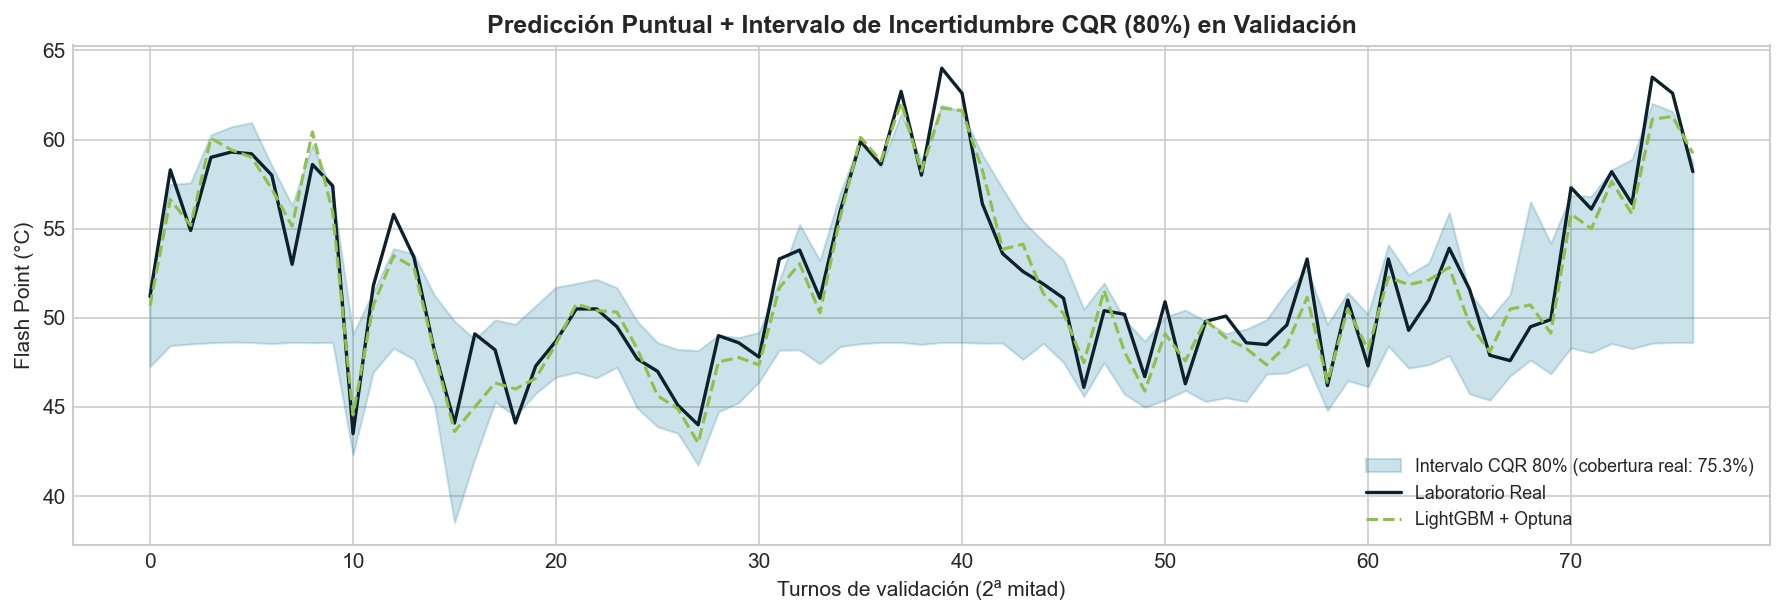

In [4]:
# Regresión Cuantílica + Calibración Conformal (CQR) para Banda 80% (P10-P90)
q_params = dict(n_estimators=90, learning_rate=0.04, max_depth=3, num_leaves=8, min_child_samples=20, random_state=42, verbose=-1)
q10 = lgb.LGBMRegressor(objective="quantile", alpha=0.10, **q_params).fit(X_train, y_train)
q90 = lgb.LGBMRegressor(objective="quantile", alpha=0.90, **q_params).fit(X_train, y_train)

# Mitad 1 de Val para calibrar el margen conforme CQR; Mitad 2 para verificación honesta
mid = len(X_val) // 2
scores_cal = np.maximum(q10.predict(X_val.iloc[:mid]) - y_val[:mid], y_val[:mid] - q90.predict(X_val.iloc[:mid]))
cqr_offset = float(np.quantile(scores_cal, 0.80 * (1.0 + 1.0 / mid)))

lo_val2 = q10.predict(X_val.iloc[mid:]) - cqr_offset
hi_val2 = q90.predict(X_val.iloc[mid:]) + cqr_offset
raw_cov = float(np.mean((y_val[mid:] >= q10.predict(X_val.iloc[mid:])) & (y_val[mid:] <= q90.predict(X_val.iloc[mid:]))))
cqr_cov = float(np.mean((y_val[mid:] >= lo_val2) & (y_val[mid:] <= hi_val2)))

print(f"Offset Conformal CQR (80% nominal): +{cqr_offset:.2f} °C")
print(f"Cobertura sin calibrar (Val-2)    : {raw_cov*100:.1f}%")
print(f"Cobertura calibrada CQR (Val-2)   : {cqr_cov*100:.1f}% | Ancho medio: {(hi_val2 - lo_val2).mean():.2f} °C")

fig, ax = plt.subplots(figsize=(12, 4.2), dpi=150)
x_idx = np.arange(len(y_val[mid:]))
ax.fill_between(x_idx, lo_val2, hi_val2, color=COLORS[0], alpha=0.20, label=f"Intervalo CQR 80% (cobertura real: {cqr_cov*100:.1f}%)")
ax.plot(x_idx, y_val[mid:], color=COLORS[4], linewidth=1.6, label="Laboratorio Real")
ax.plot(x_idx, p_opt[mid:], color=COLORS[1], linestyle="--", linewidth=1.5, label="LightGBM + Optuna")
ax.set_title("Predicción Puntual + Intervalo de Incertidumbre CQR (80%) en Validación", fontsize=12, fontweight="bold")
ax.set_xlabel("Turnos de validación (2ª mitad)")
ax.set_ylabel("Flash Point (°C)")
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

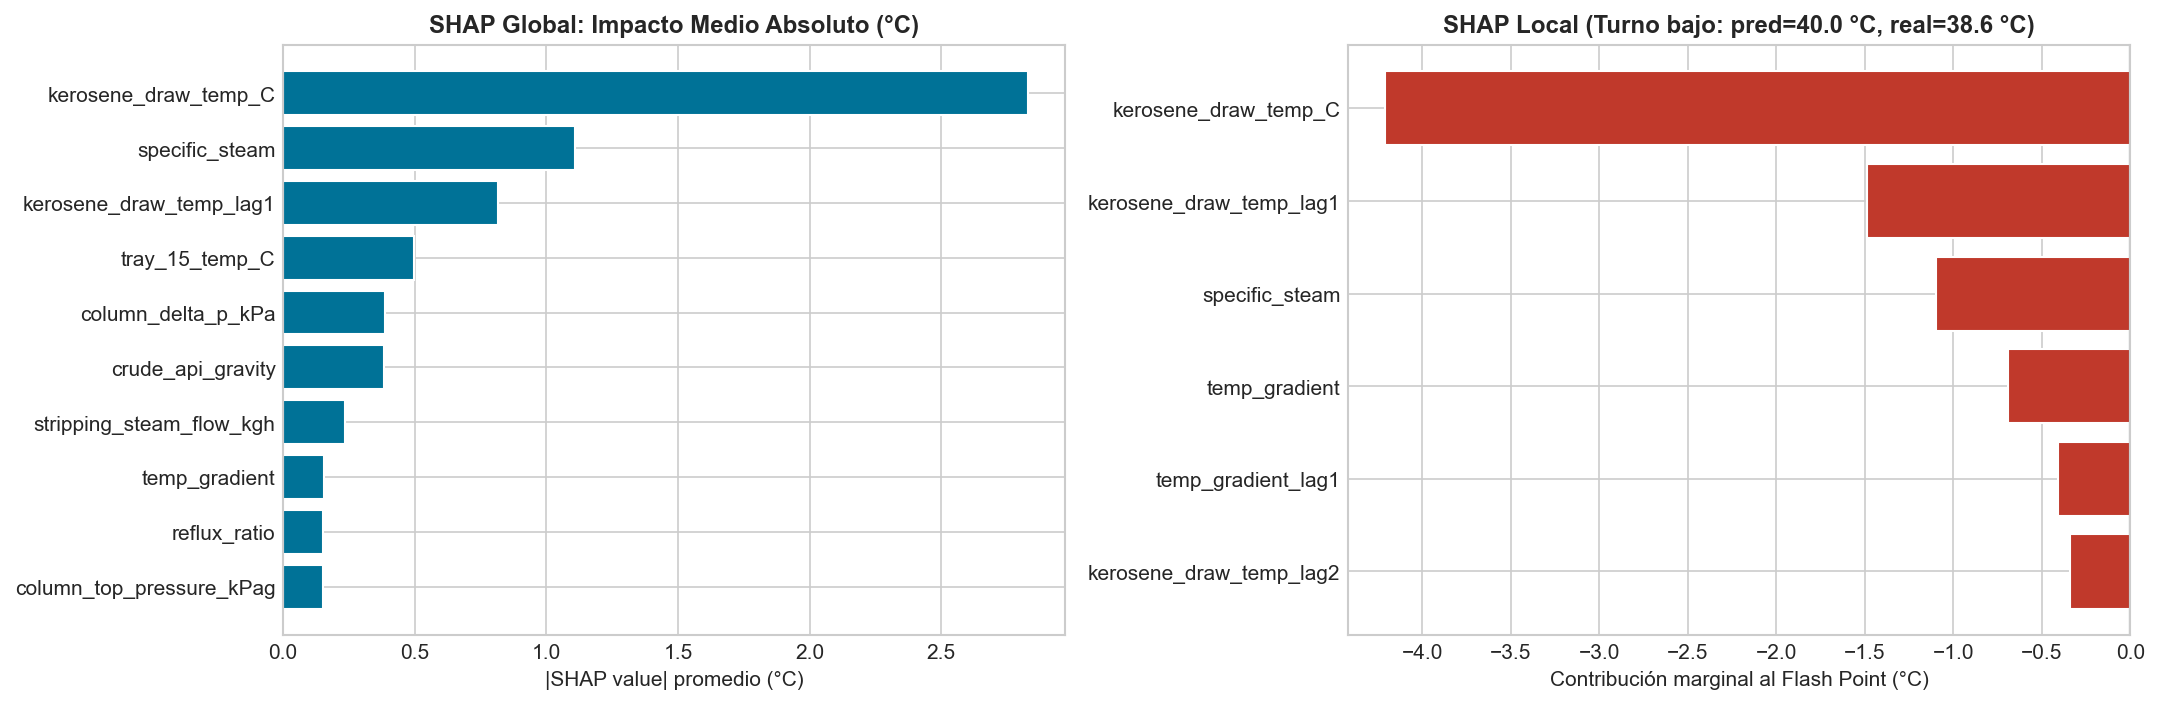

In [5]:
# Explicabilidad Global y Local con SHAP (TreeExplainer)
explainer = shap.TreeExplainer(lgb_opt)
shap_values_val = explainer.shap_values(X_val)

# 1. Importancia Global SHAP
mean_abs_shap = pd.Series(np.abs(shap_values_val).mean(axis=0), index=feature_cols).sort_values(ascending=False)
top10_shap = mean_abs_shap.head(10).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8), dpi=150)
axes[0].barh(top10_shap.index, top10_shap.values, color=COLORS[0], edgecolor="white")
axes[0].set_title("SHAP Global: Impacto Medio Absoluto (°C)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("|SHAP value| promedio (°C)")

# 2. Explicación Local (Waterfall simplificado para el turno más cercano al límite inferior)
idx_low = int(np.argmin(p_opt))
sv_local = pd.Series(shap_values_val[idx_low], index=feature_cols)
sv_top6 = sv_local.reindex(sv_local.abs().sort_values(ascending=False).head(6).index).iloc[::-1]
bar_c = [COLORS[0] if v >= 0 else COLORS[3] for v in sv_top6.values]
axes[1].barh(sv_top6.index, sv_top6.values, color=bar_c, edgecolor="white")
axes[1].axvline(0, color=COLORS[4], linewidth=1.0)
axes[1].set_title(f"SHAP Local (Turno bajo: pred={p_opt[idx_low]:.1f} °C, real={y_val[idx_low]:.1f} °C)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Contribución marginal al Flash Point (°C)")

plt.tight_layout()
plt.show()

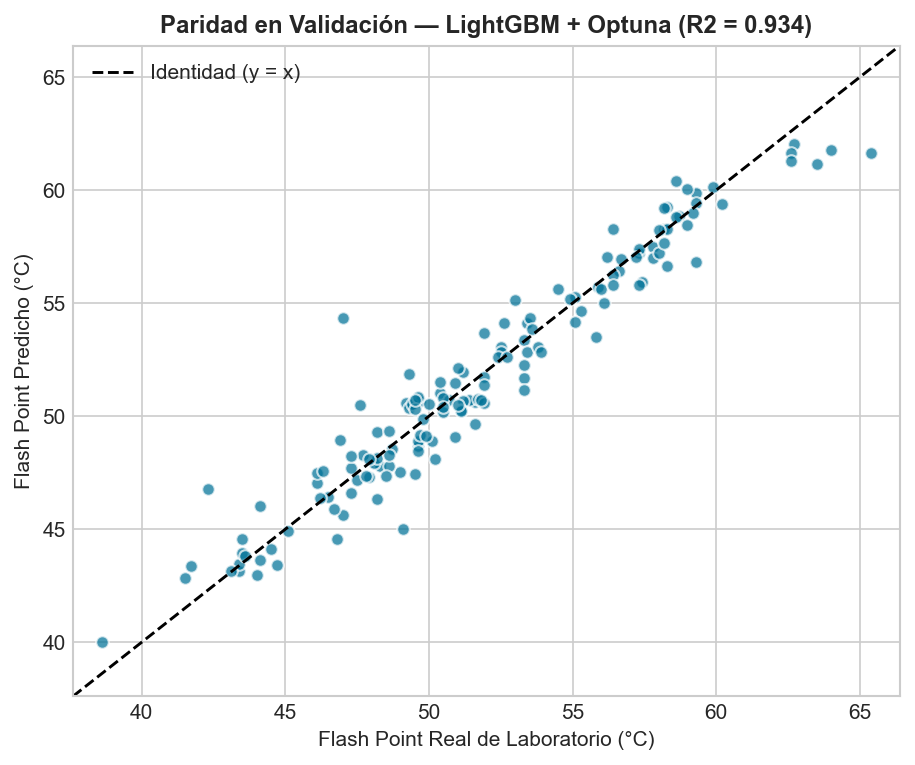

In [6]:
# Gráfica de paridad Real vs Predicho en Validación
fig, ax = plt.subplots(figsize=(6.2, 5.2), dpi=150)
ax.scatter(y_val, p_opt, color=COLORS[0], alpha=0.72, s=36, edgecolor="white")
lims = [min(y_val.min(), p_opt.min()) - 1, max(y_val.max(), p_opt.max()) + 1]
ax.plot(lims, lims, "k--", linewidth=1.4, label="Identidad (y = x)")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Flash Point Real de Laboratorio (°C)")
ax.set_ylabel("Flash Point Predicho (°C)")
ax.set_title(f"Paridad en Validación — LightGBM + Optuna (R2 = {r2_score(y_val, p_opt):.3f})", fontsize=11.5, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

### Checkpoint: Lo que debes ver

- **LightGBM** y **LightGBM + Optuna** superan claramente a PLS y los modelos lineales en Validación
- **Intervalo CQR 80%** calibrado con cobertura empírica cercana al 80% nominal
- Explicaciones **SHAP** globales y locales claras, identificando qué variables empujan la predicción hacia abajo o hacia arriba